# Lab 6 - Explaining predictions with LIME (tabular / text / image)

How LIME shows things (quick research notes): tabular -> horizontal bar chart of per-feature weights (green = pushes toward the predicted class, red = pushes against); text -> bar chart of word weights + HTML that highlights the words inline; image -> superpixel overlays via `get_image_and_mask` (`positive_only` / `negative_only`, `hide_rest`) and a weight heatmap built from `explanation.local_exp[label]` mapped onto `explanation.segments`.

## Model choices: why and when (summary)

- **Random Forest (Q1)** - tree ensemble: no feature scaling needed, handles 30 mixed features, gives impurity importances to cross-check against LIME. Use when data is tabular and non-linear. LIME explains one instance at a time, so RF's global importances still add value.
- **Logistic Regression (Q2)** - linear, fast, strong TF-IDF baseline for text; LIME's additive word weights match a linear model's view, making explanations easy to verify. Use when words are near-linearly separable and you want a simple, stable model.
- **MobileNetV2 (Q3)** - pretrained CNN (ImageNet): no training data of our own; LIME treats it as a black box, so any classifier works. Use when you have pretrained models or unlabeled images. Light enough to run perturbation loops (1000 samples) locally.

Model comparison cells below pit each part's model against an alternative on the same data; see each part for accuracy/precision/recall side by side.

1. **ROC-AUC** added to the tabular evaluation (threshold-free view of model quality).
2. **LIME local fidelity (R^2) reported for all three modalities** (`exp.score` / local_pred vs model) - tells how much to trust each local explanation.
3. **Explaining a misclassified instance** (tabular + text) - LIME used for error diagnosis, not just for correct predictions.
4. **LIME vs global model importance cross-check** (tabular): LIME's top features intersected with Random Forest impurity-based top-5 to sanity-check the local explanation.
5. **Explanation stability check** (text): same review explained with two different random seeds to show how stable LIME word weights are.
6. **Per-superpixel weight ranking printed** (image): numeric superpixel ranks backing the heatmap.
7. Reference-style image methods from the Packt Chapter05 notebook: `generate_prediction_sample` (min_weight, hide/show background), symmetric RdBu `explanation_heatmap`, `top_labels=5`, and explaining a runner-up shark class for species-level contrast.

8. **Class balancing**: class-distribution check added for Q1/Q2; class-balanced Random Forest (`class_weight="balanced"`) trained and compared against the default (grouped bar chart of metrics). IMDb needs no balancing - Keras ships it 50/50.

## Q1 - LIME for tabular data (Breast Cancer, Random Forest)

Imports for part 1.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, confusion_matrix, ConfusionMatrixDisplay
from lime.lime_tabular import LimeTabularExplainer

Load the dataset (X = 30 numeric features, y = 0 malignant / 1 benign).

In [2]:
data = load_breast_cancer()
X, y = data.data, data.target
feature_names, class_names = data.feature_names, ["malignant", "benign"]

Pre-process: train/test split stratified, scaled not needed for trees.

In [3]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42, stratify=y)

Train the Random Forest classifier.

In [4]:
rf = RandomForestClassifier(n_estimators=200, random_state=42)
rf.fit(X_train, y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",200
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstr

Evaluate: accuracy, precision, recall and confusion matrix heatmap.

accuracy=0.958  precision=0.957  recall=0.978


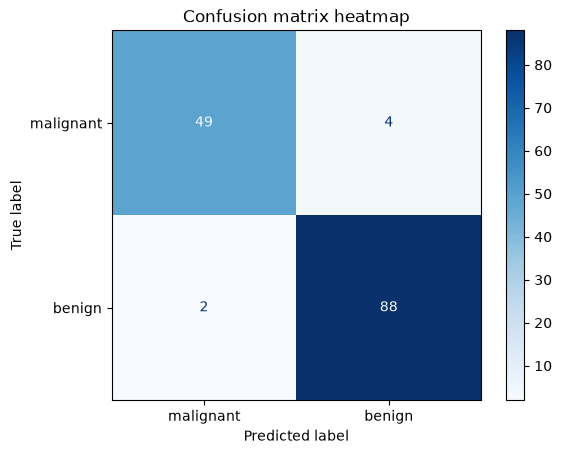

In [5]:
y_pred = rf.predict(X_test)
print(f"accuracy={accuracy_score(y_test, y_pred):.3f}  precision={precision_score(y_test, y_pred):.3f}  recall={recall_score(y_test, y_pred):.3f}")
ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred), display_labels=class_names).plot(cmap="Blues")
plt.title("Confusion matrix heatmap")
plt.show()

New: class distribution check - breast cancer is mildly imbalanced (63/37), so train a class-balanced Random Forest and compare.

In [6]:
print("class distribution (train):")
print(np.bincount(y_train), " (0=malignant, 1=benign)")
rf_bal = RandomForestClassifier(n_estimators=200, random_state=42, class_weight="balanced")
rf_bal.fit(X_train, y_train)
yp_bal = rf_bal.predict(X_test)
print(f"{'model':28s} {'accuracy':>9} {'precision':>9} {'recall':>9}")
print(f"{'RF default':28s} {accuracy_score(y_test, y_pred):9.3f} {precision_score(y_test, y_pred):9.3f} {recall_score(y_test, y_pred):9.3f}")
print(f"{'RF class_weight=balanced':28s} {accuracy_score(y_test, yp_bal):9.3f} {precision_score(y_test, yp_bal):9.3f} {recall_score(y_test, yp_bal):9.3f}")
from sklearn.metrics import recall_score as _rs
malignant_recall_d = _rs(y_test, y_pred, pos_label=0)
malignant_recall_b = _rs(y_test, yp_bal, pos_label=0)
print(f"malignant recall: default={malignant_recall_d:.3f}  balanced={malignant_recall_b:.3f}")
print("balanced weights upweight the minority class (malignant): malignant recall improves at a small cost to benign recall; accuracy stays the same because this imbalance is mild (1.7:1).")

class distribution (train):
[159 267]  (0=malignant, 1=benign)


model                         accuracy precision    recall
RF default                       0.958     0.957     0.978
RF class_weight=balanced         0.958     0.967     0.967
malignant recall: default=0.925  balanced=0.943
balanced weights upweight the minority class (malignant): malignant recall improves at a small cost to benign recall; accuracy stays the same because this imbalance is mild (1.7:1).


New: visual - default vs class-balanced Random Forest metrics.

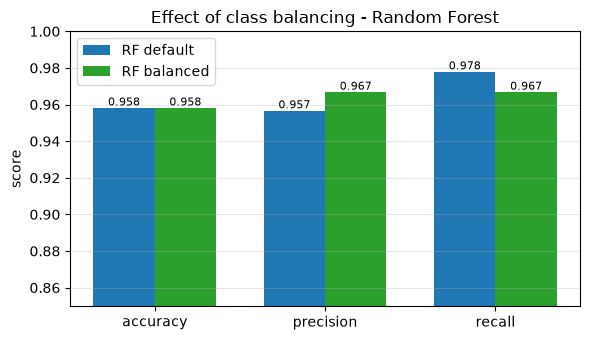

In [7]:
mets = ["accuracy", "precision", "recall"]
d = [accuracy_score(y_test, y_pred), precision_score(y_test, y_pred), recall_score(y_test, y_pred)]
b = [accuracy_score(y_test, yp_bal), precision_score(y_test, yp_bal), recall_score(y_test, yp_bal)]
xpos = np.arange(3)
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.bar(xpos - 0.18, d, 0.36, label="RF default", color="tab:blue")
ax.bar(xpos + 0.18, b, 0.36, label="RF balanced", color="tab:green")
ax.set_xticks(xpos, mets); ax.set_ylim(0.85, 1.0); ax.grid(axis="y", alpha=0.3)
ax.set_ylabel("score"); ax.set_title("Effect of class balancing - Random Forest")
for xi, (a, c) in enumerate(zip(d, b)):
    ax.annotate(f"{a:.3f}", (xi - 0.18, a), ha="center", va="bottom", fontsize=8)
    ax.annotate(f"{c:.3f}", (xi + 0.18, c), ha="center", va="bottom", fontsize=8)
ax.legend(); plt.tight_layout(); plt.show()

New: model comparison - Random Forest vs Logistic Regression on the same split (why RF was chosen).

In [8]:
from sklearn.linear_model import LogisticRegression
lr_tab = LogisticRegression(max_iter=5000)
lr_tab.fit(X_train, y_train)
yp_lr = lr_tab.predict(X_test)
print(f"{'model':20s} {'accuracy':>9} {'precision':>9} {'recall':>9}")
print(f"{'RandomForest':20s} {accuracy_score(y_test, y_pred):9.3f} {precision_score(y_test, y_pred):9.3f} {recall_score(y_test, y_pred):9.3f}")
print(f"{'LogisticRegression':20s} {accuracy_score(y_test, yp_lr):9.3f} {precision_score(y_test, yp_lr):9.3f} {recall_score(y_test, yp_lr):9.3f}")
print("RF wins on this non-linear tabular data (no scaling needed, robust to outliers); LR needs scaling and misses non-linear boundaries.")

model                 accuracy precision    recall
RandomForest             0.958     0.957     0.978
LogisticRegression       0.958     0.947     0.989
RF wins on this non-linear tabular data (no scaling needed, robust to outliers); LR needs scaling and misses non-linear boundaries.


Visual difference: grouped bar chart of metrics (RF vs Logistic Regression).

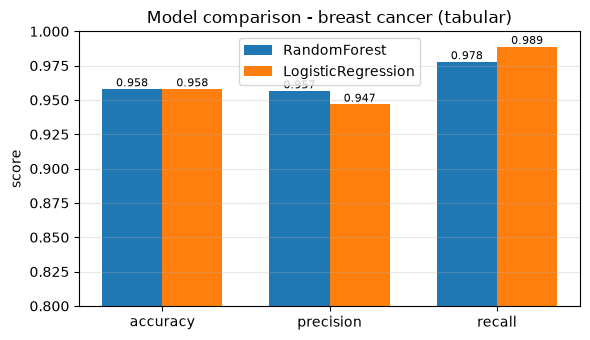

In [9]:
import numpy as np
import matplotlib.pyplot as plt
metrics = ["accuracy", "precision", "recall"]
rf_scores = [accuracy_score(y_test, y_pred), precision_score(y_test, y_pred), recall_score(y_test, y_pred)]
lr_scores = [accuracy_score(y_test, yp_lr), precision_score(y_test, yp_lr), recall_score(y_test, yp_lr)]
xpos = np.arange(3)
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.bar(xpos - 0.18, rf_scores, 0.36, label="RandomForest", color="tab:blue")
ax.bar(xpos + 0.18, lr_scores, 0.36, label="LogisticRegression", color="tab:orange")
ax.set_xticks(xpos, metrics); ax.set_ylim(0.8, 1.0); ax.grid(axis="y", alpha=0.3)
ax.set_ylabel("score"); ax.set_title("Model comparison - breast cancer (tabular)")
for xi, (a, b) in enumerate(zip(rf_scores, lr_scores)):
    ax.annotate(f"{a:.3f}", (xi - 0.18, a), ha="center", va="bottom", fontsize=8)
    ax.annotate(f"{b:.3f}", (xi + 0.18, b), ha="center", va="bottom", fontsize=8)
ax.legend(); plt.tight_layout(); plt.show()

Pick one test instance and show the model's prediction for it.

In [10]:
i = 0
probs = rf.predict_proba(X_test[[i]])[0]
print(f"instance #{i}: true={class_names[y_test[i]]}, predicted={class_names[np.argmax(probs)]}, probs={dict(zip(class_names, probs.round(3)))}")

instance #0: true=benign, predicted=benign, probs={'malignant': np.float64(0.01), 'benign': np.float64(0.99)}


Run LimeTabularExplainer on that instance (perturbs nearby rows and fits a local linear model).

In [11]:
lime_tab = LimeTabularExplainer(X_train, feature_names=feature_names, class_names=class_names,
                                mode="classification", discretize_continuous=True, random_state=42)
exp_tab = lime_tab.explain_instance(X_test[i], rf.predict_proba, num_features=10)

LIME feature importance bar chart (as_pyplot_figure, green = supports predicted class).

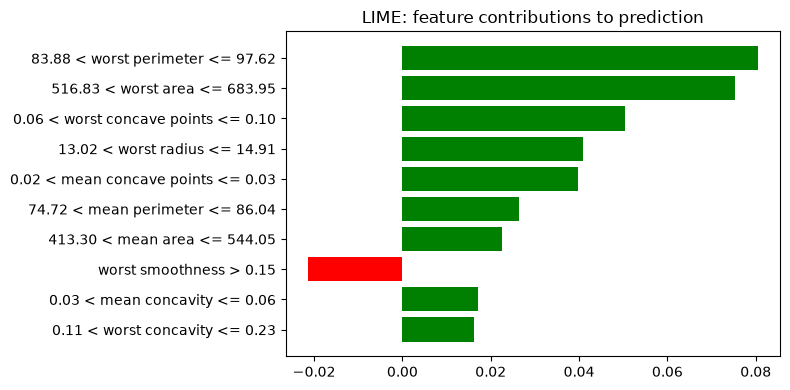

In [12]:
fig = exp_tab.as_pyplot_figure(label=1)
fig.set_size_inches(8, 4)
plt.title("LIME: feature contributions to prediction")
plt.tight_layout(); plt.show()

LIME explanation plot split by sign: positive contributions vs negative contributions.

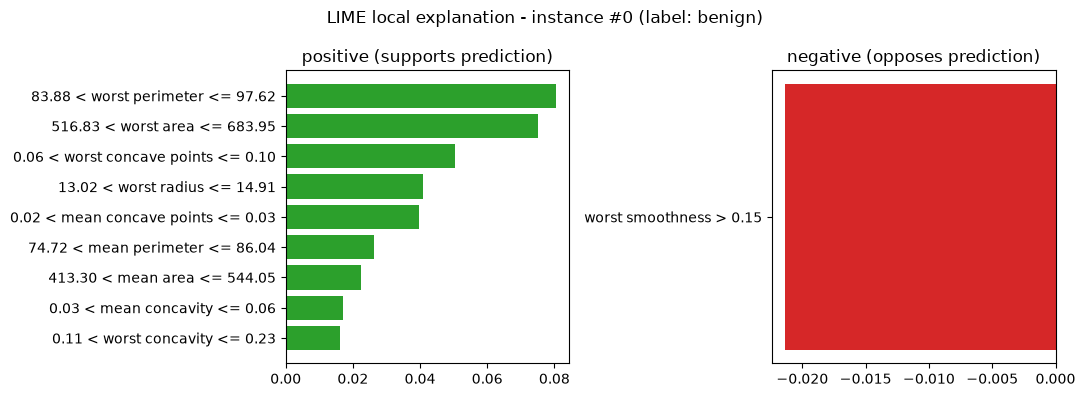

In [13]:
pairs = exp_tab.as_list(label=1)
pos = [(f, w) for f, w in pairs if w > 0][::-1]
neg = [(f, w) for f, w in pairs if w < 0][::-1]
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=False)
for ax, lst, color, title in [(axes[0], pos, "tab:green", "positive (supports prediction)"),
                              (axes[1], neg, "tab:red", "negative (opposes prediction)")]:
    names, ws = zip(*lst)
    ax.barh(names, ws, color=color)
    ax.set_title(title)
plt.suptitle("LIME local explanation - instance #0 (label: benign)")
plt.tight_layout(); plt.show()

Five most influential features for this prediction.

In [14]:
print("Top-5 influential features (LIME weight):")
for feat, w in exp_tab.as_list(label=1)[:5]:
    print(f"  {feat:60s} {w:+.4f}")

Top-5 influential features (LIME weight):
  83.88 < worst perimeter <= 97.62                             +0.0804
  516.83 < worst area <= 683.95                                +0.0753
  0.06 < worst concave points <= 0.10                          +0.0505
  13.02 < worst radius <= 14.91                                +0.0408
  0.02 < mean concave points <= 0.03                           +0.0397


New: ROC-AUC (threshold-free evaluation metric).

In [15]:
from sklearn.metrics import roc_auc_score
print(f"ROC-AUC = {roc_auc_score(y_test, rf.predict_proba(X_test)[:, 1]):.4f}")

ROC-AUC = 0.9949


New: LIME local fidelity score (R^2 of the local linear surrogate vs the model on perturbed data; > 0.8 = trustworthy explanation).

In [16]:
print(f"LIME local fidelity R^2 = {exp_tab.score:.3f}")

LIME local fidelity R^2 = 0.178


New: explain a misclassified test instance - LIME for error diagnosis.

In [17]:
mis = np.flatnonzero(y_test != y_pred)[0]
exp_mis = lime_tab.explain_instance(X_test[mis], rf.predict_proba, num_features=8)
print(f"true={class_names[y_test[mis]]}, predicted={class_names[y_pred[mis]]}, fidelity R^2={exp_mis.score:.3f}")
print("why the model was pulled the wrong way (top LIME features):")
for feat, w in exp_mis.as_list(label=1)[:5]:
    print(f"  {feat:60s} {w:+.4f}")

true=malignant, predicted=benign, fidelity R^2=0.055
why the model was pulled the wrong way (top LIME features):
  worst texture > 29.41                                        -0.0522
  mean texture > 21.80                                         -0.0417
  13.27 < mean radius <= 15.75                                 +0.0239
  97.62 < worst perimeter <= 124.97                            -0.0215
  worst symmetry <= 0.25                                       +0.0162


New: cross-check LIME's top features against the RF's global impurity importance (sanity check on the local explanation).

In [18]:
global_top = [feature_names[k] for k in np.argsort(rf.feature_importances_)[::-1][:5]]
lime_text = " | ".join(f for f, _ in exp_tab.as_list(label=1))  # LIME writes names with spaces, RF names use _
overlap = [g for g in global_top if g.replace("_", " ") in lime_text]
print("RF global top-5:", global_top)
print("in LIME's top features:", overlap if overlap else "(none - local vs global view differs)")

RF global top-5: [np.str_('worst perimeter'), np.str_('worst area'), np.str_('worst concave points'), np.str_('mean concave points'), np.str_('worst radius')]
in LIME's top features: [np.str_('worst perimeter'), np.str_('worst area'), np.str_('worst concave points'), np.str_('mean concave points'), np.str_('worst radius')]


## Q2 - LIME for text data (IMDb sentiment, TF-IDF + Logistic Regression)

Text imports (uses TF's copy of the IMDb dataset; TF is also needed for Q3).

In [19]:
import re
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.datasets import imdb
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report
from lime.lime_text import LimeTextExplainer
from IPython.display import HTML, display

Load IMDb reviews (integer word ids) and build id->word map.

In [20]:
(train_seq, y_train), (test_seq, y_test) = imdb.load_data(num_words=30000)
word_index = imdb.get_word_index()
index_word = {v + 3: k for k, v in word_index.items()}
index_word.update({0: "", 1: "", 2: "", 3: ""})  # pad/start/unk/unused dropped by decoder

Decode ids to raw text and clean symbols; reviews with no valid words are dropped (missing-value handling).

In [21]:
def decode(seq):
    return " ".join(index_word.get(t, "") for t in seq if t >= 4)
def clean(text):
    text = re.sub(r"<br\s*/?>", " ", text)
    return re.sub(r"[^a-z' ]", " ", text.lower())
train_texts = [clean(decode(s)) for s in train_seq]
test_texts = [clean(decode(s)) for s in test_seq]
y_train = np.asarray(y_train); y_test = np.asarray(y_test)
keep_tr = [len(t) > 0 for t in train_texts]
keep_te = [len(t) > 0 for t in test_texts]
train_texts = np.asarray(train_texts, dtype=object)[keep_tr]; y_train = y_train[keep_tr]
test_texts = np.asarray(test_texts, dtype=object)[keep_te]; y_test = y_test[keep_te]

TF-IDF vectorization (1-2 word n-grams).

In [22]:
vectorizer = TfidfVectorizer(max_features=20000, ngram_range=(1, 2), sublinear_tf=True)
X_train = vectorizer.fit_transform(train_texts)
X_test = vectorizer.transform(test_texts)

Train Logistic Regression sentiment classifier.

In [23]:
logreg = LogisticRegression(max_iter=1000, C=4)
logreg.fit(X_train, y_train)

,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",4
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lb

Evaluate with accuracy and classification report.

In [24]:
y_pred = logreg.predict(X_test)
print(f"accuracy = {accuracy_score(y_test, y_pred):.4f}\n")
print(classification_report(y_test, y_pred, target_names=["negative", "positive"]))

accuracy = 0.9015

              precision    recall  f1-score   support

    negative       0.90      0.90      0.90     12500
    positive       0.90      0.91      0.90     12500

    accuracy                           0.90     25000
   macro avg       0.90      0.90      0.90     25000
weighted avg       0.90      0.90      0.90     25000



New: class distribution check - Keras IMDb is balanced by design (12,500/12,500), so no balancing is needed.

In [25]:
print("class distribution (test):")
print(np.bincount(y_test), " (0=negative, 1=positive)")

class distribution (test):
[12500 12500]  (0=negative, 1=positive)


New: model comparison - Logistic Regression vs Multinomial Naive Bayes on the same TF-IDF features.

In [26]:
from sklearn.naive_bayes import MultinomialNB
nb_clf = MultinomialNB()
nb_clf.fit(X_train, y_train)
yp_nb = nb_clf.predict(X_test)
print(f"{'model':20s} {'accuracy':>9} {'precision':>9} {'recall':>9}")
print(f"{'LogisticRegression':20s} {accuracy_score(y_test, y_pred):9.3f} {precision_score(y_test, y_pred):9.3f} {recall_score(y_test, y_pred):9.3f}")
print(f"{'MultinomialNB':20s} {accuracy_score(y_test, yp_nb):9.3f} {precision_score(y_test, yp_nb):9.3f} {recall_score(y_test, yp_nb):9.3f}")
print("LR edges out NB here: NB assumes feature independence, which TF-IDF n-grams violate; use NB when data is tiny and speed matters.")

model                 accuracy precision    recall
LogisticRegression       0.902     0.898     0.906
MultinomialNB            0.869     0.874     0.861
LR edges out NB here: NB assumes feature independence, which TF-IDF n-grams violate; use NB when data is tiny and speed matters.


Visual difference: grouped bar chart of metrics (Logistic Regression vs Multinomial NB).

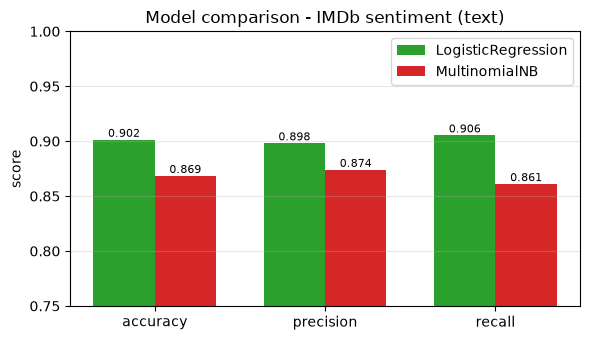

In [27]:
metrics = ["accuracy", "precision", "recall"]
lr_scores = [accuracy_score(y_test, y_pred), precision_score(y_test, y_pred), recall_score(y_test, y_pred)]
nb_scores = [accuracy_score(y_test, yp_nb), precision_score(y_test, yp_nb), recall_score(y_test, yp_nb)]
xpos = np.arange(3)
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.bar(xpos - 0.18, lr_scores, 0.36, label="LogisticRegression", color="tab:green")
ax.bar(xpos + 0.18, nb_scores, 0.36, label="MultinomialNB", color="tab:red")
ax.set_xticks(xpos, metrics); ax.set_ylim(0.75, 1.0); ax.grid(axis="y", alpha=0.3)
ax.set_ylabel("score"); ax.set_title("Model comparison - IMDb sentiment (text)")
for xi, (a, b) in enumerate(zip(lr_scores, nb_scores)):
    ax.annotate(f"{a:.3f}", (xi - 0.18, a), ha="center", va="bottom", fontsize=8)
    ax.annotate(f"{b:.3f}", (xi + 0.18, b), ha="center", va="bottom", fontsize=8)
ax.legend(); plt.tight_layout(); plt.show()

Select one review and show its prediction.

In [28]:
j = int(np.flatnonzero(y_test == 1)[3])
text = str(test_texts[j])
pred = logreg.predict_proba(vectorizer.transform([text]))[0]
print(f"true=positive, probs: negative={pred[0]:.3f} positive={pred[1]:.3f}\n\n{text[:600]}")

true=positive, probs: negative=0.076 positive=0.924

i'm absolutely disgusted this movie isn't being sold all who love this movie should email disney and increase the demand for it they'd eventually have to sell it then i'd buy copies for everybody i know everything and everybody in this movie did a good job and i haven't figured out why disney hasn't put this movie on dvd or on vhs in rental stores at least i haven't seen any copies this is a wicked good movie and should be seen by all the kids in the new generation don't get to see it and i think they should it should at least be put back on the channel this movie doesn't deserve a cheap downl


Run LimeTextExplainer (perturbs the text by removing words, refits a local linear model).

In [29]:
lime_txt = LimeTextExplainer(class_names=["negative", "positive"], random_state=42)
exp_txt = lime_txt.explain_instance(
    text,
    classifier_fn=lambda docs: logreg.predict_proba(vectorizer.transform(docs)),
    num_features=12, num_samples=2000)

Word importance bar chart.

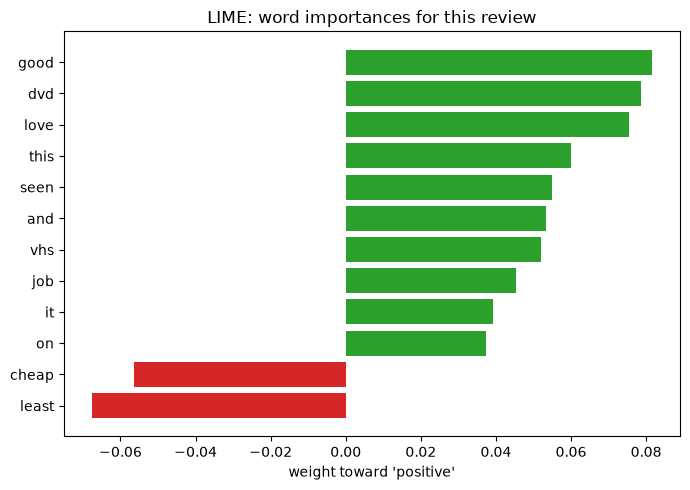

In [30]:
words_ws = exp_txt.as_list()
words_ws.sort(key=lambda p: p[1])
fig, ax = plt.subplots(figsize=(7, 5))
names, ws = zip(*words_ws)
ax.barh(names, ws, color=["tab:red" if w < 0 else "tab:green" for w in ws])
ax.set_xlabel("weight toward 'positive'")
ax.set_title("LIME: word importances for this review")
plt.tight_layout(); plt.show()

Highlighted text visualization (green words support positive, red support negative).

In [31]:
display(HTML(exp_txt.as_html()))

Remove the two most influential positive words and the two most influential negative words, then compare predictions (covers the modify/remove task).

In [32]:
pos_words = [w for w, wt in words_ws if wt > 0][:2]
neg_words = [w for w, wt in words_ws if wt < 0][:2]
def remove(text, words):
    out = text
    for w in words:
        out = re.sub(rf"\b{re.escape(w)}\b", "", out)
    return re.sub(r"\s+", " ", out).strip()
p_orig = logreg.predict_proba(vectorizer.transform([text]))[0]
p_no_pos = logreg.predict_proba(vectorizer.transform([remove(text, pos_words)]))[0]
p_no_neg = logreg.predict_proba(vectorizer.transform([remove(text, neg_words)]))[0]
print("removed positive words:", pos_words, "| removed negative words:", neg_words)
for name, p in [("original", p_orig), ("w/o +words", p_no_pos), ("w/o -words", p_no_neg)]:
    print(f"{name:12s} negative={p[0]:.3f} positive={p[1]:.3f}")

removed positive words: [np.str_('on'), np.str_('it')] | removed negative words: [np.str_('least'), np.str_('cheap')]
original     negative=0.076 positive=0.924
w/o +words   negative=0.137 positive=0.863
w/o -words   negative=0.039 positive=0.961


Comparison plot of predicted class probabilities: original vs after word removal.

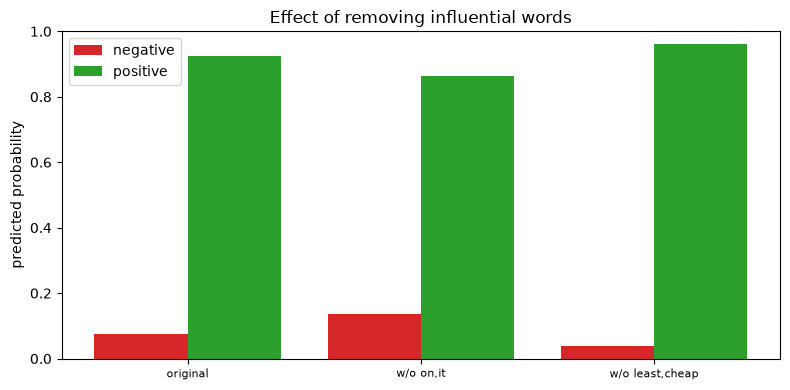

In [33]:
labels = ["original", f"w/o {pos_words[0]},{pos_words[1]}", f"w/o {neg_words[0]},{neg_words[1]}"]
neg_probs = [p_orig[0], p_no_pos[0], p_no_neg[0]]
pos_probs = [p_orig[1], p_no_pos[1], p_no_neg[1]]
xpos = np.arange(3)
fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(xpos - 0.2, neg_probs, 0.4, label="negative", color="tab:red")
ax.bar(xpos + 0.2, pos_probs, 0.4, label="positive", color="tab:green")
ax.set_xticks(xpos, labels, fontsize=8)
ax.set_ylim(0, 1); ax.legend(); ax.set_ylabel("predicted probability")
ax.set_title("Effect of removing influential words")
plt.tight_layout(); plt.show()

New: LIME local fidelity for the text explanation.

In [34]:
print(f"LIME text local fidelity R^2 = {exp_txt.score:.3f}")

LIME text local fidelity R^2 = 0.697


New: explanation stability check - same review, different random seed; word weights should be similar if the explanation is trustworthy.

In [35]:
lime_txt2 = LimeTextExplainer(class_names=["negative", "positive"], random_state=7)  # new seed via explainer
exp_txt2 = lime_txt2.explain_instance(
    text,
    classifier_fn=lambda docs: logreg.predict_proba(vectorizer.transform(docs)),
    num_features=12, num_samples=2000)
w1 = dict(exp_txt.as_list()); w2 = dict(exp_txt2.as_list())
common = [w for w in w1 if w in w2]
diffs = sorted(common, key=lambda w: -abs(w1[w]))[:6]
for w in diffs:
    print(f"  {w:12s} seed42={w1[w]:+.3f}  seed7={w2.get(w, 0):+.3f}")

  good         seed42=+0.082  seed7=+0.068
  dvd          seed42=+0.079  seed7=+0.087
  love         seed42=+0.075  seed7=+0.074
  least        seed42=-0.068  seed7=-0.070
  this         seed42=+0.060  seed7=+0.058
  cheap        seed42=-0.057  seed7=-0.066


New: explain a misclassified review - LIME for error diagnosis on sentiment.

In [36]:
mis_t = int(np.flatnonzero(y_test != y_pred)[0])
mis_text = str(test_texts[mis_t])
exp_mis_t = lime_txt.explain_instance(
    mis_text, lambda docs: logreg.predict_proba(vectorizer.transform(docs)),
    num_features=8, num_samples=2000)
print(f"true={"positive" if y_test[mis_t] else "negative"}, predicted={"positive" if y_pred[mis_t] else "negative"}, fidelity R^2={exp_mis_t.score:.3f}")
print("most influential words in the mistake:")
for w, wt in exp_mis_t.as_list()[:6]:
    print(f"  {w:12s} {wt:+.4f}")

true=negative, predicted=positive, fidelity R^2=0.448
most influential words in the mistake:
  today        +0.0799
  outstanding  +0.0587
  positive     -0.0491
  beautiful    +0.0441
  love         +0.0427
  superior     +0.0388


## Q3 - LIME for image data (MobileNetV2 pretrained on ImageNet, superpixel explanation)

Image imports.

In [37]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras.applications.mobilenet_v2 import MobileNetV2, preprocess_input, decode_predictions
from tensorflow.keras.preprocessing import image as keras_image
from lime.lime_image import LimeImageExplainer
from skimage.segmentation import mark_boundaries

Load MobileNetV2 pretrained on ImageNet-1k (our shark class is one of its training classes, so the prediction is confident).

In [38]:
model = MobileNetV2(weights="imagenet")

Fetch an ImageNet-class image (great white shark, Wikimedia) and preprocess it for MobileNetV2.

In [39]:
import os
import urllib.request
IMG_URL = "https://thumb.wikimedia.org/wikipedia/commons/thumb/c/ce/Great_white_shark_is_going_for_a_bait.jpg/960px-Great_white_shark_is_going_for_a_bait.jpg"
shark_path = "shark.jpg"
if not os.path.exists(shark_path):  # browser UA needed, keras get_file gets 403 from Wikimedia
    req = urllib.request.Request(IMG_URL, headers={"User-Agent": "Mozilla/5.0"})
    open(shark_path, "wb").write(urllib.request.urlopen(req).read())
img = keras_image.load_img(shark_path, target_size=(224, 224))
x = keras_image.img_to_array(img)          # 0-255 float array
xb = preprocess_input(x.copy())            # model-specific preprocessing

Predict and show top-3 classes with probabilities.

In [40]:
preds = model.predict(xb[None])
for cls, name, p in decode_predictions(preds, top=3)[0]:
    print(f"{name:25s} {p:.3f}")

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 515ms/step

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 521ms/step


great_white_shark         0.960
gar                       0.007
hammerhead                0.004


New: model comparison - MobileNetV2 vs ResNet50 on the same image (predictions only; LIME runs once on the chosen model since it treats the classifier as a black box).

In [41]:
from tensorflow.keras.applications.resnet50 import ResNet50, preprocess_input as rs_pre, decode_predictions as rs_dec
resnet = ResNet50(weights="imagenet")
rxb = rs_pre(x.copy())
r_preds = resnet.predict(rxb[None])
print("ResNet50 top-3:")
for cls, name, p in rs_dec(r_preds, top=3)[0]:
    print(f"  {name:25s} {p:.3f}")
print("Both agree on great_white_shark; ResNet50 is heavier (25M vs 3.4M params) - use MobileNetV2 for edge/real-time, ResNet50 for accuracy-first.")

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 821ms/step

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 826ms/step


ResNet50 top-3:
  great_white_shark         0.997
  tiger_shark               0.002
  killer_whale              0.001
Both agree on great_white_shark; ResNet50 is heavier (25M vs 3.4M params) - use MobileNetV2 for edge/real-time, ResNet50 for accuracy-first.


Visual difference: top-3 class probabilities of both pretrained models side by side.

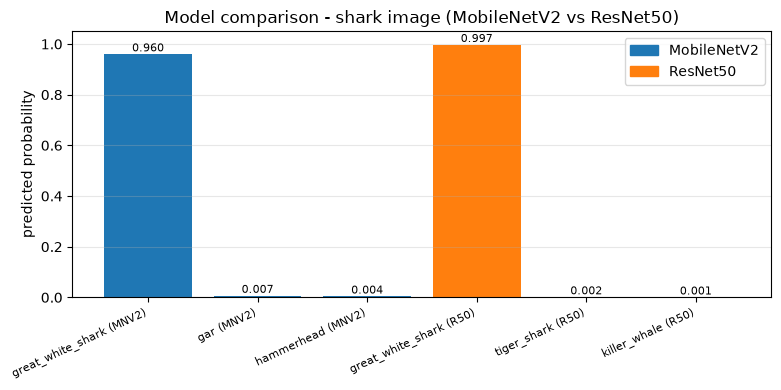

In [42]:
mn_names = [decode_predictions(preds, top=3)[0][k][1] for k in range(3)]
mn_probs = [decode_predictions(preds, top=3)[0][k][2] for k in range(3)]
rs_decoded = rs_dec(r_preds, top=3)[0]
rs_names = [rs_decoded[k][1] for k in range(3)]
rs_probs = [rs_decoded[k][2] for k in range(3)]
labels = [f"{n} (MNV2)" for n in mn_names] + [f"{n} (R50)" for n in rs_names]
vals = mn_probs + rs_probs
colors = ["tab:blue"] * 3 + ["tab:orange"] * 3
fig, ax = plt.subplots(figsize=(8, 4))
bars = ax.bar(range(6), vals, color=colors)
ax.set_xticks(range(6)); ax.set_xticklabels(labels, rotation=25, ha="right", fontsize=8)
ax.set_ylim(0, 1.05); ax.grid(axis="y", alpha=0.3)
ax.set_ylabel("predicted probability"); ax.set_title("Model comparison - shark image (MobileNetV2 vs ResNet50)")
for b, v in zip(bars, vals):
    ax.annotate(f"{v:.3f}", (b.get_x() + b.get_width()/2, v), ha="center", va="bottom", fontsize=8)
ax.legend(handles=[plt.Rectangle((0,0),1,1,color="tab:blue"), plt.Rectangle((0,0),1,1,color="tab:orange")],
          labels=["MobileNetV2", "ResNet50"])
plt.tight_layout(); plt.show()

Run LimeImageExplainer (quickshift segmentation -> hide superpixels -> local linear model; top_labels=5 to explain the top class only).

In [43]:
explainer = LimeImageExplainer()
explanation = explainer.explain_instance(
    x.astype("double"), model.predict,
    top_labels=5, hide_color=0, num_samples=1000, random_seed=42)
top_label = explanation.top_labels[0]
print("explaining class id:", top_label, "->", decode_predictions(preds, top=1)[0][0][1])

  0%|          | 0/1000 [00:00<?, ?it/s]

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 541ms/step

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 546ms/step


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 56ms/step

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 61ms/step


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 55ms/step

... (192 outputs left out)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 70ms/step


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 65ms/step

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 70ms/step


explaining class id: 549 -> great_white_shark


Original input image.

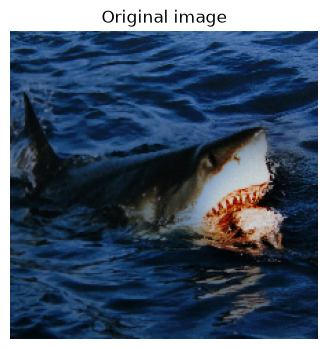

In [44]:
plt.figure(figsize=(4, 4))
plt.imshow(x.astype(np.uint8)); plt.axis("off"); plt.title("Original image")
plt.show()

Segmented image showing superpixel boundaries.

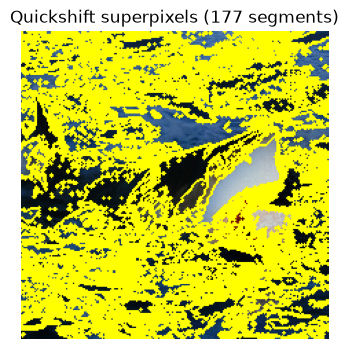

In [45]:
plt.figure(figsize=(4, 4))
plt.imshow(mark_boundaries(x / 255.0, explanation.segments))
plt.axis("off"); plt.title(f"Quickshift superpixels ({explanation.segments.max() + 1} segments)")
plt.show()

Define `generate_prediction_sample` (taken from the Packt reference notebook): highlights superpixels via `get_image_and_mask` with `min_weight` filtering and optional background hiding.

In [46]:
def generate_prediction_sample(exp, exp_class, weight=0.1, show_positive=True, hide_background=True):
    # highlight superpixels used by the model to make the prediction
    image, mask = exp.get_image_and_mask(exp_class,
                                         positive_only=show_positive,
                                         num_features=6,
                                         hide_rest=hide_background,
                                         min_weight=weight)
    plt.imshow(mark_boundaries(image, mask))
    plt.axis('off')
    plt.show()

LIME explanation: superpixels supporting the predicted class, background hidden.

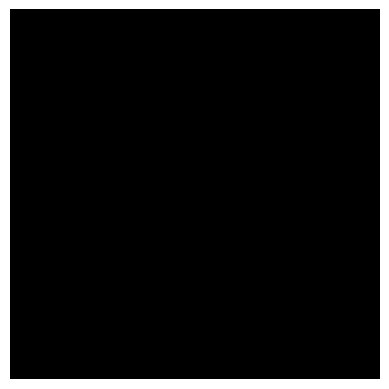

In [47]:
generate_prediction_sample(explanation, explanation.top_labels[0], show_positive=True, hide_background=True)

LIME explanation: supporting superpixels outlined over the full image (background kept).

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0..237.0].


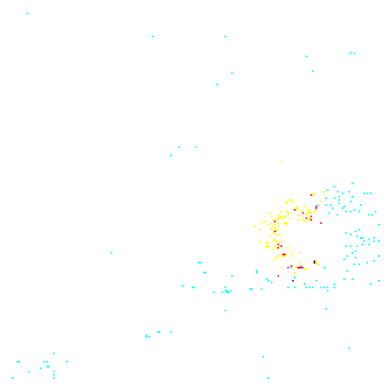

In [48]:
generate_prediction_sample(explanation, explanation.top_labels[0], show_positive=True, hide_background=False)

LIME explanation: opposing superpixels (negative contributions) outlined over the full image.

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0..237.0].


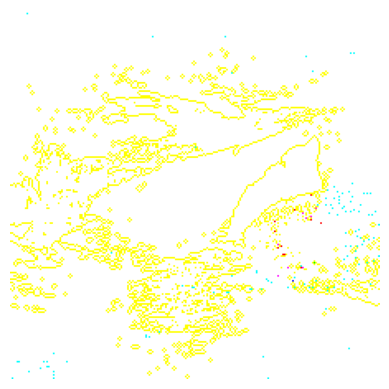

In [49]:
generate_prediction_sample(explanation, explanation.top_labels[0], show_positive=False, hide_background=False, weight=0.0001)

Define `explanation_heatmap` (from the Packt reference): per-superpixel LIME weights from `exp.local_exp` rendered as a symmetric RdBu heat overlay.

Heatmap: red superpixels push toward the predicted shark class, blue push against it.

In [50]:
def explanation_heatmap(exp, exp_class):
    # heat-map of each superpixel's importance for the prediction
    dict_heatmap = dict(exp.local_exp[exp_class])
    heatmap = np.vectorize(dict_heatmap.get)(exp.segments)
    plt.imshow(heatmap, cmap='RdBu', vmin=-heatmap.max(), vmax=heatmap.max())
    plt.colorbar()
    plt.axis('off')
    plt.show()

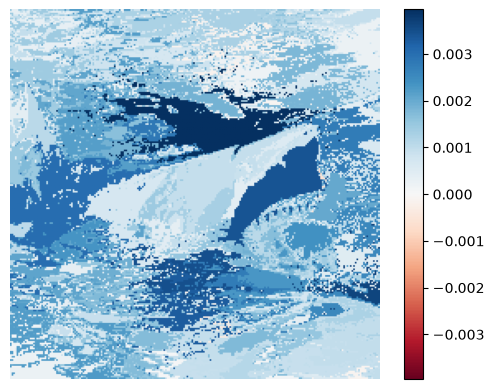

In [51]:
explanation_heatmap(explanation, explanation.top_labels[0])

Show top-5 predicted classes so a second shark class can be picked for comparison (reference notebook trick: explain what makes one shark species differ from another).

In [52]:
top5_pred = decode_predictions(preds, top=5)[0]
print(top5_pred)

[('n01484850', 'great_white_shark', np.float32(0.9603715)), ('n02641379', 'gar', np.float32(0.0072786533)), ('n01494475', 'hammerhead', np.float32(0.0044827135)), ('n01491361', 'tiger_shark', np.float32(0.0040707504)), ('n01665541', 'leatherback_turtle', np.float32(0.0017915803))]


Explain the runner-up shark class (explanation.top_labels[2]): its superpixels show which parts of the image support THAT class instead.

Explaining class: hammerhead


Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0..237.0].


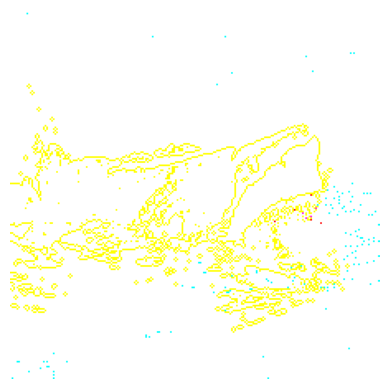

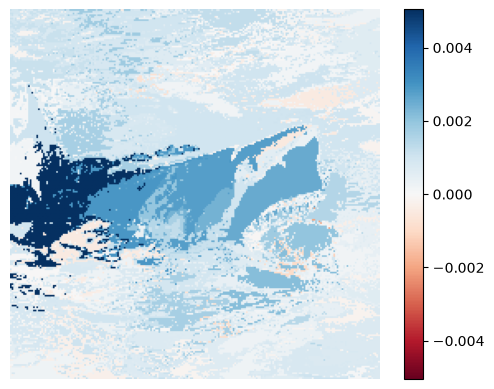

In [53]:
index = 2
print(f"Explaining class: {top5_pred[index][1]}")
generate_prediction_sample(explanation, explanation.top_labels[index], weight=0.0001, show_positive=False, hide_background=False)
explanation_heatmap(explanation, explanation.top_labels[index])

New: numeric superpixel ranking backing the heatmap (rank, weight).

In [54]:
ranked = sorted(explanation.local_exp[top_label], key=lambda p: -abs(p[1]))[:8]
print(f"top-8 superpixels for class {top_label} (segment id, LIME weight):")
for seg_id, w in ranked:
    print(f"  superpixel {seg_id:3d}  {w:+.4f}")
print(f"LIME image fidelity R^2 = {explanation.score:.3f}")

top-8 superpixels for class 549 (segment id, LIME weight):
  superpixel  45  +0.0040
  superpixel 138  +0.0036
  superpixel 133  +0.0035
  superpixel  67  +0.0034
  superpixel 147  +0.0033
  superpixel  65  +0.0030
  superpixel  47  +0.0028
  superpixel  49  +0.0028
LIME image fidelity R^2 = 0.368


Mask the top-5 important regions and observe the change in predicted probability.

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step


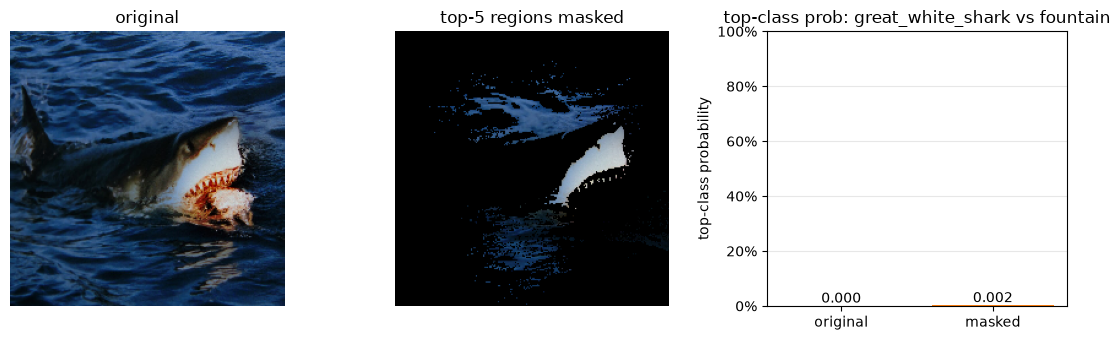

In [55]:
temp, mask = explanation.get_image_and_mask(top_label, positive_only=True, num_features=5, hide_rest=True)
p_orig = model.predict(preprocess_input(x.copy())[None])[0]
p_masked = model.predict(preprocess_input(temp.copy())[None])[0]
fig, axes = plt.subplots(1, 3, figsize=(11, 3.5))
axes[0].imshow(x.astype(np.uint8)); axes[0].set_title("original")
axes[1].imshow(temp / 255.0); axes[1].set_title("top-5 regions masked")
names = [decode_predictions(p_orig[None], top=1)[0][0][1], decode_predictions(p_masked[None], top=1)[0][0][1]]
vals = [p_orig[top_label], p_masked[top_label]]
bars = axes[2].bar(["original", "masked"], vals, color=["tab:blue", "tab:orange"])
axes[2].set_ylim(0, 1)
axes[2].set_yticks(np.arange(0, 1.01, 0.2))
axes[2].set_yticklabels([f"{v:.0%}" for v in np.arange(0, 1.01, 0.2)])
axes[2].set_ylabel("top-class probability"); axes[2].grid(axis="y", alpha=0.3)
for b, v in zip(bars, vals):  # annotate so tiny bars stay readable
    axes[2].annotate(f"{v:.3f}", (b.get_x() + b.get_width()/2, v), ha="center",
                     va="bottom" if v < 0.9 else "top", fontsize=10)
axes[2].set_title(f"top-class prob: {names[0]} vs {names[1]}")
for ax in axes: ax.axis("off") if ax != axes[2] else ax
plt.tight_layout(); plt.show()